# 실습 08 · 일일프로젝트: 문장 하나가 LLM 출력이 되기까지 (기본필수)

02~07에서 따로 계산한 단계를 **문장 하나로 이어서** 한 번에 따라갑니다.

`입력 문장` → `Token·ID (02)` → `Embedding·Cosine (03)` → `Attention·Mask (05)` → `Logit·Softmax·선택 (06)` → `요약 문서`

### 사용 방법
1. **결과는 이미 셀 아래에 저장되어 있습니다.** 읽기만 해도 흐름을 따라갈 수 있어요.
2. 직접 돌려 보려면 `파일 → Drive에 사본 저장`으로 내 사본을 만드세요.
3. 맨 위 **⚙️ 준비 셀을 먼저 한 번 실행**한 뒤, 보고 싶은 구간의 셀을 실행하세요. 각 구간은 준비 셀만 있으면 따로 실행됩니다.
4. **✏️ 표시 셀**은 오른쪽 입력 칸의 값을 바꾸고 실행해 보세요. 코드의 값도 함께 바뀝니다.

> ⚠️ 교육용 수치 예제를 이어 붙인 것이며 실제 학습된 LLM·RAG·Agent가 아닙니다. 그림 렌더링은 mermaid.ink 이미지를 사용하므로 인터넷 연결이 필요합니다.

In [1]:
#@title ⚙️ 먼저 실행하세요 — 실습 공통 코드 준비
# ── 원본: 20261113/mentor/01_basic/common/support.py (그대로 포함) ──
"""강의 공통 오프라인 계산 도구: 실제 사전학습 LLM이 아닙니다.

교육용 정규표현식 토큰화·작은 벡터·가중치 계산만 제공합니다.
Transformer의 tokenizer/embedding 품질을 이 도구로 평가할 수 없습니다.
"""
from pathlib import Path
import json
import math
import re
import torch

DATA = [
    {"id":"A", "title":"실습 파일 보관", "content":"실습 파일은 개인 폴더에 보관합니다.", "category":"learning"},
    {"id":"B", "title":"서버 실행", "content":"프로젝트 폴더에서 서버를 실행합니다.", "category":"environment"},
    {"id":"C", "title":"질문 작성", "content":"오류 메시지와 시도한 작업을 함께 적습니다.", "category":"learning"},
]
SPECIAL = ["[PAD]", "[UNK]", "[BOS]", "[EOS]"]

def words(text: str) -> list[str]:
    """교육용: 한글 연속 글자/영문/숫자/문장부호 분리. 서브워드 토크나이저가 아님."""
    return re.findall(r'[가-힣]+|[A-Za-z]+|\d+|[^\w\s]', text)

class ToyTokenizer:
    """BERT tokenizer 대체가 아닌, 오프라인 개념 확인용 규칙 기반 어휘표."""
    def __init__(self, corpus):
        wordset=sorted({word for line in corpus for word in words(line)})
        self.vocab={tok:i for i,tok in enumerate(SPECIAL + wordset)}
        self.reverse={i:t for t,i in self.vocab.items()}

    def encode(self, text: str, max_length=None, padding_to=None):
        raw=words(text)
        tokens=["[BOS]"]+raw+["[EOS]"]
        truncated=False
        if max_length is not None:
            if max_length<2: raise ValueError("BOS/EOS를 포함하려면 max_length>=2")
            if len(tokens)>max_length:
                tokens=tokens[:max_length-1]+["[EOS]"]
                truncated=True
        valid=len(tokens)
        if padding_to is not None:
            if padding_to<valid: raise ValueError("padding_to must be >= valid length")
            tokens=tokens+["[PAD]"]*(padding_to-valid)
        ids=[self.vocab.get(t,self.vocab["[UNK]"]) for t in tokens]
        mask=[0 if t=="[PAD]" else 1 for t in tokens]
        return {"tokens":tokens,"input_ids":ids,"attention_mask":mask,
                "valid_length":valid,"truncated":truncated,"original_length":len(raw)+2}

    def batch(self, texts, max_length=None):
        items=[self.encode(t,max_length=max_length) for t in texts]
        max_size=max(len(i["input_ids"]) for i in items)
        return [self.encode(t,max_length=max_length,padding_to=max_size) for t in texts]

def context_budget(window, parts:dict, output_reserved:int):
    used=sum(parts.values())
    return {"window":window,"input_used":used,"output_reserved":output_reserved,
            "remaining":window-used-output_reserved,
            "fits":used+output_reserved<=window}

def cosine(a,b):
    a=torch.as_tensor(a,dtype=torch.float32)
    b=torch.as_tensor(b,dtype=torch.float32)
    return float(torch.nn.functional.cosine_similarity(a,b,dim=0))

def attention(q,k,v,causal=True):
    q=torch.as_tensor(q,dtype=torch.float32)
    k=torch.as_tensor(k,dtype=torch.float32)
    v=torch.as_tensor(v,dtype=torch.float32)
    scores=q@k.T/math.sqrt(q.shape[-1])
    mask=torch.triu(torch.ones_like(scores,dtype=torch.bool),diagonal=1)
    weights=torch.softmax(scores.masked_fill(mask,float('-inf')) if causal else scores,dim=-1)
    return scores,weights,weights@v,mask

def write_json(path, data):
    p=Path(path);p.parent.mkdir(exist_ok=True,parents=True)
    p.write_text(json.dumps(data,ensure_ascii=False,indent=2),encoding='utf-8')

def write_md(path,text):
    p=Path(path);p.parent.mkdir(exist_ok=True,parents=True)
    p.write_text(text,encoding='utf-8')

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

# ── 노트북 전용 준비 ──
import pandas as pd
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

import base64
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

torch.manual_seed(42)
torch.set_num_threads(1)

# 08은 A/B/C 문장만으로 사전을 만듭니다 (02와 사전이 달라 ID도 다릅니다)
texts = [d["content"] for d in DATA]
tokenizer = ToyTokenizer(texts)

def token_table(record):
    return pd.DataFrame([record["tokens"], record["input_ids"], record["attention_mask"]],
                        index=["token", "id", "mask"])

def heatmap(matrix, title):
    m = matrix.detach().numpy()
    fig, ax = plt.subplots(figsize=(3.4, 3))
    ax.imshow(m, cmap="Blues", vmin=0, vmax=1)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center",
                    color="white" if m[i, j] > 0.6 else "black")
    ax.set_xticks(range(3), ["t0", "t1", "t2"]); ax.set_yticks(range(3), ["t0", "t1", "t2"])
    ax.set_xlabel("Key"); ax.set_ylabel("Query"); ax.set_title(title)
    plt.show()

def show_mermaid(mermaid_code):
    """Mermaid 텍스트를 그림으로 보여 줌 (mermaid.ink 이미지, 인터넷 필요)"""
    encoded = base64.urlsafe_b64encode(mermaid_code.encode("utf-8")).decode("ascii")
    display(Image(url="https://mermaid.ink/img/" + encoded))

print("준비 완료 ✅  사전 크기:", len(tokenizer.vocab))

준비 완료 ✅  사전 크기: 20


## B01. 입력 문장 → Token·ID (02 복습)
지식 A 문장을 Token으로 바꾸고, Context 한도 12 안에 들어가는지 확인합니다.

In [2]:
input_sentence = DATA[0]["content"]
token_report = tokenizer.encode(input_sentence, max_length=12)
token_table(token_report)

,0,1,2,3,4,5,6,7
token,[BOS],실습,파일은,개인,폴더에,보관합니다,.,[EOS]
id,2,10,15,5,16,7,4,3
mask,1,1,1,1,1,1,1,1


In [3]:
print("입력 길이(특수 Token 포함):", token_report["valid_length"], "/ 한도 12")
print("잘렸나?:", token_report["truncated"])
assert token_report["valid_length"] <= 12
print("B01 통과 ✅")

입력 길이(특수 Token 포함): 8 / 한도 12
잘렸나?: False
B01 통과 ✅


### ✏️ B01 직접 해 보기 — 긴 문장을 넣으면?

In [4]:
#@title ✏️ 문장과 한도를 바꿔 보세요
sentence = "실습 파일은 개인 폴더에 보관합니다."  #@param {type:"string"}
max_length = 12  #@param {type:"slider", min:2, max:16, step:1}

rec = tokenizer.encode(sentence, max_length=max_length)
print(f"원래 {rec['original_length']}개 → {rec['valid_length']}개", "(잘림 ❌)" if rec["truncated"] else "(그대로 ✅)")
token_table(rec)

원래 8개 → 8개 (그대로 ✅)


,0,1,2,3,4,5,6,7
token,[BOS],실습,파일은,개인,폴더에,보관합니다,.,[EOS]
id,2,10,15,5,16,7,4,3
mask,1,1,1,1,1,1,1,1


## B02. Embedding·Cosine (03 복습)
교육용 2D 벡터에서 A와 비슷한 방향의 문장을 찾습니다.

In [5]:
coords = {"A": [1., 0.], "B": [.8, .2], "C": [-1., 0.]}
cosine_table = {f"A_{k}": cosine(coords["A"], v) for k, v in coords.items() if k != "A"}
pd.Series(cosine_table, name="cosine").round(4).to_frame()

,cosine
A_B,0.9701
A_C,-1.0000


In [6]:
nearest = max(cosine_table, key=cosine_table.get)
print("A와 가장 비슷한 방향:", nearest)
assert nearest == "A_B" and cosine_table["A_C"] == -1.0
print("B02 통과 ✅")

A와 가장 비슷한 방향: A_B
B02 통과 ✅


## B03. Attention·Causal Mask (05 복습)
공통 함수 `attention()`이 Score → Mask → Softmax → Output을 한 번에 계산합니다.

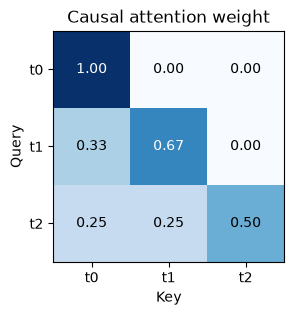

In [7]:
q = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
scores, weights, attn_out, mask = attention(q, q, q, causal=True)
heatmap(weights, "Causal attention weight")

In [8]:
print("행 합       :", weights.sum(dim=-1).tolist())
print("미래 칸 값  :", weights[mask].tolist())
assert torch.allclose(weights.sum(dim=-1), torch.ones(3))
assert torch.all(weights[mask] == 0)
print("B03 통과 ✅")

행 합       : [1.0, 1.0, 1.0]
미래 칸 값  : [0.0, 0.0, 0.0]
B03 통과 ✅


## B04. Logit → Softmax → 다음 Token (06 복습)

In [9]:
logits = torch.tensor([2., 1., 0.])
probs = torch.softmax(logits, dim=0)
selected = int(probs.argmax().item())
next_token = ["출력A", "출력B", "출력C"][selected]
pd.DataFrame({"후보": ["출력A", "출력B", "출력C"], "Logit": logits.tolist(),
              "확률": probs.round(decimals=3).tolist()})

,후보,Logit,확률
0,출력A,2.0,0.665
1,출력B,1.0,0.245
2,출력C,0.0,0.090


In [10]:
print("다음 Token:", next_token)
assert next_token == "출력A"
print("B04 통과 ✅")

다음 Token: 출력A
B04 통과 ✅


## B05. 한 장 요약 만들기
앞 단계 결과를 `one_page_summary.md`의 내용으로 엮습니다. 아래 셀은 B01~B04 값을 다시 계산해 문서 줄을 만듭니다.

In [11]:
input_sentence = DATA[0]["content"]
token_report = tokenizer.encode(input_sentence, max_length=12)
coords = {"A": [1., 0.], "B": [.8, .2], "C": [-1., 0.]}
cosine_table = {f"A_{k}": cosine(coords["A"], v) for k, v in coords.items() if k != "A"}
q = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
scores, weights, attn_out, mask = attention(q, q, q, causal=True)
next_token = ["출력A", "출력B", "출력C"][int(torch.softmax(torch.tensor([2., 1., 0.]), dim=0).argmax())]

flow = ["flowchart LR",
        "  U[입력 문장] --> T[Token/ID] --> E[Embedding] --> A[Attention/Mask] --> L[Logit/Softmax] --> O[다음 Token]",
        "  R[후속 Retriever] -. 검색 근거 .-> T", "  DB[(원본 PostgreSQL)] -. 원본/메타데이터 .-> R",
        "  F[FastAPI] -. 입력/응답 .-> U"]
summary_lines = [
    f"- Token 및 Special Token 포함 입력 길이: {token_report['valid_length']}",
    f"- Token IDs: {token_report['input_ids']}",
    f"- 교육용 Cosine A-B / A-C: {cosine_table['A_B']:.4f} / {cosine_table['A_C']:.4f}",
    f"- Causal Mask Attention Row Sum: {weights.sum(dim=-1).tolist()}",
    f"- 다음 Token 예시 선택: {next_token}",
]
display(Markdown("\n".join(summary_lines)))

- Token 및 Special Token 포함 입력 길이: 8
- Token IDs: [2, 10, 15, 5, 16, 7, 4, 3]
- 교육용 Cosine A-B / A-C: 0.9701 / -1.0000
- Causal Mask Attention Row Sum: [1.0, 1.0, 1.0]
- 다음 Token 예시 선택: 출력A

점선은 **후속 수업**(RAG·Retriever)에서 붙을 연결입니다.

In [12]:
show_mermaid("\n".join(flow))

## 저장. 결과 저장 (`main.py`와 같은 결과)
`outputs/one_page_summary.md`와 `outputs/daily_project.json`을 저장합니다. 이 셀은 준비 셀만 있으면 혼자 실행됩니다.

In [13]:
input_sentence = DATA[0]["content"]
token_report = tokenizer.encode(input_sentence, max_length=12)
assert token_report["valid_length"] <= 12

coords = {"A": [1., 0.], "B": [.8, .2], "C": [-1., 0.]}
cosine_table = {f"A_{k}": cosine(coords["A"], v) for k, v in coords.items() if k != "A"}

q = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
scores, weights, attn_out, mask = attention(q, q, q, causal=True)
assert torch.allclose(weights.sum(dim=-1), torch.ones(3))
assert torch.all(weights[mask] == 0)

logits = torch.tensor([2., 1., 0.])
probs = torch.softmax(logits, dim=0)
selected = int(probs.argmax().item())
next_token = ["출력A", "출력B", "출력C"][selected]

platform_map = {"FastAPI": "요청·응답", "PostgreSQL": "원본 저장", "LLM": "Token 출력",
                "RAG": "외부 근거(후속)", "Agent": "도구 제어(후속)"}
limitations = ["교육용 수치 예제는 실제 학습된 LLM과 다르다"]

lines = [
    "# 일일프로젝트: 문장 하나가 LLM 출력이 되기까지", "",
    f"입력: {input_sentence}", "",
    f"- Token 및 Special Token 포함 입력 길이: {token_report['valid_length']}",
    f"- Token IDs: {token_report['input_ids']}",
    f"- 교육용 Cosine A-B / A-C: {cosine_table['A_B']:.4f} / {cosine_table['A_C']:.4f}",
    f"- Causal Mask Attention Row Sum: {weights.sum(dim=-1).tolist()}",
    f"- 다음 Token 예시 선택: {next_token}", "",
    "```mermaid", "flowchart LR", "  U[입력 문장] --> T[Token/ID] --> E[Embedding] --> A[Attention/Mask] --> L[Logit/Softmax] --> O[다음 Token]",
    "  R[후속 Retriever] -. 검색 근거 .-> T", "  DB[(원본 PostgreSQL)] -. 원본/메타데이터 .-> R",
    "  F[FastAPI] -. 입력/응답 .-> U", "```", "",
    "주의: 그림은 개념적 위치 표시이며 오늘 실제 RAG·Agent 서비스를 실행한 것이 아닙니다.",
]
write_md(OUT_DIR / "one_page_summary.md", "\n".join(lines) + "\n")

write_json(OUT_DIR / "daily_project.json", {
    "source_data": DATA, "token": token_report, "cosine": cosine_table,
    "scores_shape": list(scores.shape), "attention_weights": weights.tolist(),
    "row_sums": weights.sum(dim=-1).tolist(), "causal_mask": mask.tolist(),
    "logits": logits.tolist(), "probabilities": probs.tolist(),
    "next_token_demo": next_token, "custom_token_lengths": [],
    "masked_unmasked_l1": None, "platform": platform_map,
    "limitations": limitations, "scope": "교육용 독립 수치 계산; 실제 LLM/RAG/Agent 아님",
})
print("[08] daily_project.json + one_page_summary.md 생성 완료")

[08] daily_project.json + one_page_summary.md 생성 완료


In [14]:
print((OUT_DIR / "one_page_summary.md").read_text(encoding="utf-8"))

# 일일프로젝트: 문장 하나가 LLM 출력이 되기까지

입력: 실습 파일은 개인 폴더에 보관합니다.

- Token 및 Special Token 포함 입력 길이: 8
- Token IDs: [2, 10, 15, 5, 16, 7, 4, 3]
- 교육용 Cosine A-B / A-C: 0.9701 / -1.0000
- Causal Mask Attention Row Sum: [1.0, 1.0, 1.0]
- 다음 Token 예시 선택: 출력A

```mermaid
flowchart LR
  U[입력 문장] --> T[Token/ID] --> E[Embedding] --> A[Attention/Mask] --> L[Logit/Softmax] --> O[다음 Token]
  R[후속 Retriever] -. 검색 근거 .-> T
  DB[(원본 PostgreSQL)] -. 원본/메타데이터 .-> R
  F[FastAPI] -. 입력/응답 .-> U
```

주의: 그림은 개념적 위치 표시이며 오늘 실제 RAG·Agent 서비스를 실행한 것이 아닙니다.



In [15]:
#@title 📥 결과 파일 내려받기 (Colab)
if IN_COLAB:
    from google.colab import files
    for name in ['daily_project.json', 'one_page_summary.md']:
        files.download(str(OUT_DIR / name))
else:
    print("Colab에서 실행하면 결과 파일이 내려받아집니다:", ['daily_project.json', 'one_page_summary.md'])

Colab에서 실행하면 결과 파일이 내려받아집니다: ['daily_project.json', 'one_page_summary.md']


---
### 정리 — 문장 하나가 LLM 출력이 되기까지
1. 문장을 **Token·ID**로 바꾸고 Context 한도 안에 있는지 확인한다.
2. **Embedding** 벡터의 방향으로 비슷한 문장을 찾는다 (Cosine).
3. **Attention**으로 Token끼리 참고하되, Causal Mask로 미래는 보지 않는다.
4. **Logit → Softmax**로 확률을 만들고 다음 Token을 고른다.
5. 실제 서비스에서는 FastAPI·PostgreSQL·후속 RAG가 이 흐름 앞뒤에 붙는다.